In [14]:
%pip install pandas numpy openpyxl geopandas shapely matplotlib folium cartopy requests

Note: you may need to restart the kernel to use updated packages.


Import the libraries

In [15]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
import requests

from shapely.geometry import LineString
from IPython.display import display

print("All libraries imported successfully!")

All libraries imported successfully!


Download the port dataset

In [16]:
ports_url = (
    "https://github.com/magisAR9/JE-Ormuz/"
    "raw/refs/heads/main/PORTS_monde.xlsx"
)

ports = pd.read_excel(ports_url, engine="openpyxl")

In [17]:
print("Dataset dimensions:", ports.shape)

print("\nColumn names:")
print(ports.columns.tolist())

display(ports.head())

Dataset dimensions: (5727, 5)

Column names:
['PortID', 'PortName', 'Country', 'LatitudeDecimal', 'LongitudeDecimal']


,PortID,PortName,Country,LatitudeDecimal,LongitudeDecimal
0,10003,Funafuti,Tuvalu,-8.516666,179.216667
1,10004,Famagusta,Cyprus,35.131917,33.944950
2,10005,Withnell Bay,Australia,-20.584350,116.760383
3,10006,Crinan Canal,United Kingdom,56.091433,-5.556000
4,10008,Porthmadog,United Kingdom,52.923400,-4.128850


Check and clean the port dataset

In [18]:
# Check missing values
print(ports.isnull().sum())

# Check duplicated records
print("Duplicates:", ports.duplicated().sum())

# Check data types
print(ports.dtypes)

PortID              0
PortName            0
Country             0
LatitudeDecimal     0
LongitudeDecimal    0
dtype: int64
Duplicates: 0
PortID                int64
PortName                str
Country                 str
LatitudeDecimal     float64
LongitudeDecimal    float64
dtype: object


In [19]:
ports["LatitudeDecimal"] = pd.to_numeric(
    ports["LatitudeDecimal"], errors="coerce"
)

ports["LongitudeDecimal"] = pd.to_numeric(
    ports["LongitudeDecimal"], errors="coerce"
)

ports = ports.dropna(
    subset=["LatitudeDecimal", "LongitudeDecimal"]
)

ports = ports[
    ports["LatitudeDecimal"].between(-90, 90) &
    ports["LongitudeDecimal"].between(-180, 180)
]

print("Cleaned dataset:", ports.shape)

Cleaned dataset: (5727, 5)


Create your GeoDataFrame

In [20]:
geoports = gpd.GeoDataFrame(
    ports,
    geometry=gpd.points_from_xy(
        ports["LongitudeDecimal"],
        ports["LatitudeDecimal"]
    ),
    crs="EPSG:4326"
)

display(geoports.head())

,PortID,PortName,Country,LatitudeDecimal,LongitudeDecimal,geometry
0,10003,Funafuti,Tuvalu,-8.516666,179.216667,POINT (179.21667 -8.51667)
1,10004,Famagusta,Cyprus,35.131917,33.944950,POINT (33.94495 35.13192)
2,10005,Withnell Bay,Australia,-20.584350,116.760383,POINT (116.76038 -20.58435)
3,10006,Crinan Canal,United Kingdom,56.091433,-5.556000,POINT (-5.556 56.09143)
4,10008,Porthmadog,United Kingdom,52.923400,-4.128850,POINT (-4.12885 52.9234)


first map of the world's ports

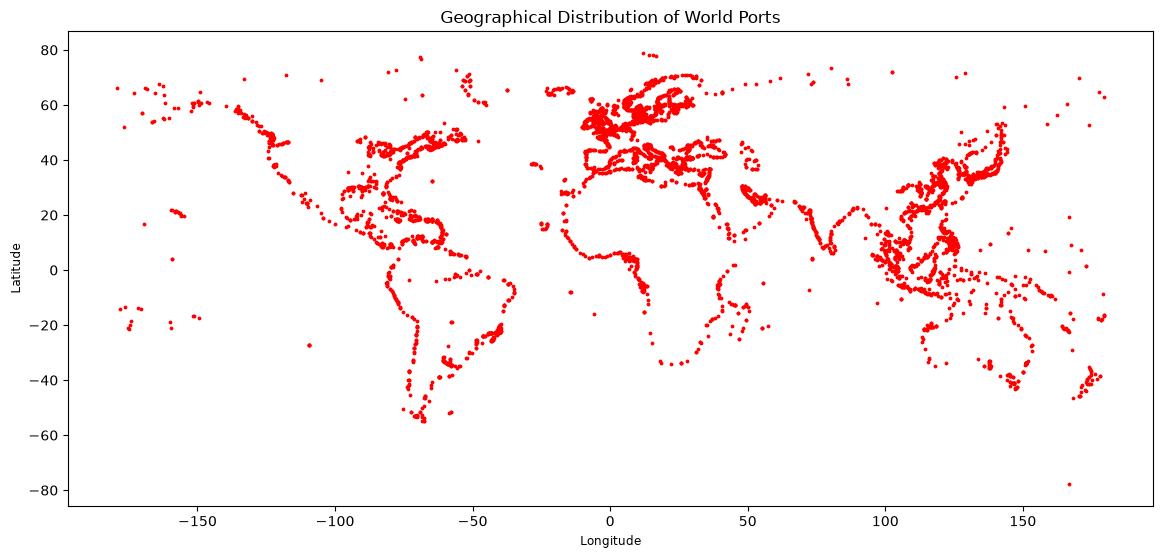

In [21]:
ax = geoports.plot(
    figsize=(14, 8),
    markersize=3,
    color="red"
)

ax.set_title("Geographical Distribution of World Ports")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

Study the ports around Hormuz

Load the Hormuz port dataset

In [22]:
from pathlib import Path

data_folder = Path(r"C:\Users\kolla\OneDrive\Desktop\Msc_GGL\3rd Semister\Geospatial and web development\Project Ormuz\Data")

file_ports = data_folder / "PORTS_monde.xlsx"

file_hormuz = data_folder / "ESCALES PC GNL ET TANKER.xlsx"

file_world = data_folder / "ESCALES_GDS_TANKERS_+55000dwt.xlsx"

In [23]:
for file in [file_ports, file_hormuz, file_world]:
    print(file.name, file.exists())

PORTS_monde.xlsx True
ESCALES PC GNL ET TANKER.xlsx True
ESCALES_GDS_TANKERS_+55000dwt.xlsx True


Step 9. Read the Excel files

In [24]:
ports_W = pd.read_excel(file_ports)

# Read the PORTS sheet
ports_detroit_ormuz = pd.read_excel(
    file_hormuz,
    sheet_name="PORTS"
)

# Read all sheets from the two datasets
xls_hormuz = pd.ExcelFile(file_hormuz)
xls_world = pd.ExcelFile(file_world)

print("Hormuz sheets:", xls_hormuz.sheet_names)
print("World tanker sheets:", xls_world.sheet_names)

Hormuz sheets: ['PC', 'GNL', 'CHEMICAL & OIL TANKER', 'PORTS', 'DESCRIPTION DES CHAMPS']
World tanker sheets: ['Feuil1']


In [25]:
print("World ports:", ports_W.shape)
print("Hormuz ports:", ports_detroit_ormuz.shape)

display(ports_detroit_ormuz.head())

World ports: (5727, 5)
Hormuz ports: (64, 4)


,Port,Country,LatitudeDecimal,LongitudeDecimal
0,Salalah,Oman,16.950300,54.025067
1,Jebel Ali,United Arab Emirates,25.026700,55.032417
2,Bandar Imam Khomeini,Iran,30.419550,49.061217
3,Bandar Abbas,Iran,27.169700,56.281617
4,Assaluyeh,Iran,27.526967,52.536000


Display the 64 Hormuz ports on an interactive map

In [26]:
# Calculate the centre of the map
center_lat = ports_detroit_ormuz["LatitudeDecimal"].mean()
center_lon = ports_detroit_ormuz["LongitudeDecimal"].mean()

# Create map
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=6,
    tiles="OpenStreetMap"
)

# Add port locations
for _, row in ports_detroit_ormuz.iterrows():

    folium.CircleMarker(
        location=[
            row["LatitudeDecimal"],
            row["LongitudeDecimal"]
        ],
        radius=5,
        popup=f'{row["Port"]}, {row["Country"]}',
        color="purple",
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

m

In [27]:
m.save("Hormuz_ports.html")

Analyse the tanker port calls

Understand the tanker datasets

In [28]:
# Inspect the available sheets
for sheet in xls_hormuz.sheet_names:

    df = pd.read_excel(file_hormuz, sheet_name=sheet)

    print("\nSHEET:", sheet)
    print("Dimensions:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


SHEET: PC
Dimensions: (5187, 11)
Columns: ['IMO/LR/IHS No.', 'MMSI', 'Ship Name', 'Operator', 'Port', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Vessel Type', 'Prev Port', 'Voyage Hours']


,IMO/LR/IHS No.,MMSI,Ship Name,Operator,Port,Arrival Time,Sailed Time,Hours in Port,Vessel Type,Prev Port,Voyage Hours
0,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Salalah,2026-01-19 00:11:00,2026-01-19 20:00:00,19.816667,CONTAINER SHIP,Tanger-Mediterranean,528
1,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Jebel Ali,2026-01-22 20:15:00,2026-01-24 01:47:00,29.533333,CONTAINER SHIP,Salalah,72
2,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Salalah,2026-02-04 22:54:00,2026-02-05 18:14:00,19.333333,CONTAINER SHIP,Jawaharlal Nehru Port,69



SHEET: GNL
Dimensions: (931, 13)
Columns: ['IMO/LR/IHS No.', 'Port', 'Port Zone', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']


,IMO/LR/IHS No.,Port,Port Zone,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9443401,Ras Laffan,Ras Laffan,Zeebrugge,538003354.0,AAMIRA,Qatargas Liquefied Gas Co Ltd,LIQUEFIED GAS TANKER,2025-12-04 11:52:00,2025-12-06 04:09:00,40.283333,856,130026
1,9443401,Ras Laffan,Ras Laffan,Incheon,538003354.0,AAMIRA,Qatargas Liquefied Gas Co Ltd,LIQUEFIED GAS TANKER,2026-01-27 09:20:00,2026-01-28 14:12:00,28.866667,753,130026
2,9412062,Ruwais,Ruwais,Jawaharlal Nehru Port,636025577.0,ADMAR,Columbia Shipmanagement Ltd,LIQUEFIED GAS TANKER,2026-01-14 03:02:00,2026-01-14 21:17:00,18.250000,197,26540



SHEET: CHEMICAL & OIL TANKER
Dimensions: (5139, 12)
Columns: ['IMO/LR/IHS No.', 'Port', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']


,IMO/LR/IHS No.,Port,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9411563,Port Rashid,Hamriyah Free Zone Port,372577000.0,A.S. RUBY RED,Aslan Shipping Services,TANKER,2025-12-26 14:00:00,2025-12-28 11:47:00,45.783333,7.0,12885
1,9142502,Khor Fakkan,Durban,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-06 09:52:00,2026-01-07 08:31:00,22.650000,627.0,6649
2,9142502,Khor Fakkan,Karwar,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-25 08:47:00,2026-01-27 09:16:00,48.483333,141.0,6649



SHEET: PORTS
Dimensions: (64, 4)
Columns: ['Port', 'Country', 'LatitudeDecimal', 'LongitudeDecimal']


,Port,Country,LatitudeDecimal,LongitudeDecimal
0,Salalah,Oman,16.95030,54.025067
1,Jebel Ali,United Arab Emirates,25.02670,55.032417
2,Bandar Imam Khomeini,Iran,30.41955,49.061217



SHEET: DESCRIPTION DES CHAMPS
Dimensions: (13, 3)
Columns: ['CHAMP', 'Description ', 'Précisions éventuelles']


,CHAMP,Description,Précisions éventuelles
0,IMO/LR/IHS No.,Numéro d'identification unique du navire attri...,NaN
1,MMSI,Identifiant numérique unique à 9 chiffres attr...,NaN
2,Port,Nom du port dans lequel le navire effectue une...,NaN


In [29]:
# Inspect the available sheets
for sheet in xls_hormuz.sheet_names:

    df = pd.read_excel(file_hormuz, sheet_name=sheet)

    print("\nSHEET:", sheet)
    print("Dimensions:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


SHEET: PC
Dimensions: (5187, 11)
Columns: ['IMO/LR/IHS No.', 'MMSI', 'Ship Name', 'Operator', 'Port', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Vessel Type', 'Prev Port', 'Voyage Hours']


,IMO/LR/IHS No.,MMSI,Ship Name,Operator,Port,Arrival Time,Sailed Time,Hours in Port,Vessel Type,Prev Port,Voyage Hours
0,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Salalah,2026-01-19 00:11:00,2026-01-19 20:00:00,19.816667,CONTAINER SHIP,Tanger-Mediterranean,528
1,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Jebel Ali,2026-01-22 20:15:00,2026-01-24 01:47:00,29.533333,CONTAINER SHIP,Salalah,72
2,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Salalah,2026-02-04 22:54:00,2026-02-05 18:14:00,19.333333,CONTAINER SHIP,Jawaharlal Nehru Port,69



SHEET: GNL
Dimensions: (931, 13)
Columns: ['IMO/LR/IHS No.', 'Port', 'Port Zone', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']


,IMO/LR/IHS No.,Port,Port Zone,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9443401,Ras Laffan,Ras Laffan,Zeebrugge,538003354.0,AAMIRA,Qatargas Liquefied Gas Co Ltd,LIQUEFIED GAS TANKER,2025-12-04 11:52:00,2025-12-06 04:09:00,40.283333,856,130026
1,9443401,Ras Laffan,Ras Laffan,Incheon,538003354.0,AAMIRA,Qatargas Liquefied Gas Co Ltd,LIQUEFIED GAS TANKER,2026-01-27 09:20:00,2026-01-28 14:12:00,28.866667,753,130026
2,9412062,Ruwais,Ruwais,Jawaharlal Nehru Port,636025577.0,ADMAR,Columbia Shipmanagement Ltd,LIQUEFIED GAS TANKER,2026-01-14 03:02:00,2026-01-14 21:17:00,18.250000,197,26540



SHEET: CHEMICAL & OIL TANKER
Dimensions: (5139, 12)
Columns: ['IMO/LR/IHS No.', 'Port', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']


,IMO/LR/IHS No.,Port,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9411563,Port Rashid,Hamriyah Free Zone Port,372577000.0,A.S. RUBY RED,Aslan Shipping Services,TANKER,2025-12-26 14:00:00,2025-12-28 11:47:00,45.783333,7.0,12885
1,9142502,Khor Fakkan,Durban,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-06 09:52:00,2026-01-07 08:31:00,22.650000,627.0,6649
2,9142502,Khor Fakkan,Karwar,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-25 08:47:00,2026-01-27 09:16:00,48.483333,141.0,6649



SHEET: PORTS
Dimensions: (64, 4)
Columns: ['Port', 'Country', 'LatitudeDecimal', 'LongitudeDecimal']


,Port,Country,LatitudeDecimal,LongitudeDecimal
0,Salalah,Oman,16.95030,54.025067
1,Jebel Ali,United Arab Emirates,25.02670,55.032417
2,Bandar Imam Khomeini,Iran,30.41955,49.061217



SHEET: DESCRIPTION DES CHAMPS
Dimensions: (13, 3)
Columns: ['CHAMP', 'Description ', 'Précisions éventuelles']


,CHAMP,Description,Précisions éventuelles
0,IMO/LR/IHS No.,Numéro d'identification unique du navire attri...,NaN
1,MMSI,Identifiant numérique unique à 9 chiffres attr...,NaN
2,Port,Nom du port dans lequel le navire effectue une...,NaN


In [30]:
for sheet in xls_world.sheet_names:

    df = pd.read_excel(file_world, sheet_name=sheet)

    print("\nSHEET:", sheet)
    print("Dimensions:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


SHEET: Feuil1
Dimensions: (30753, 13)
Columns: ['IMO/LR/IHS No.', 'MMSI', 'Ship Name', 'Operator', 'Port', 'Port Zone', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'DWT', 'Arrival Draught', 'Departure Draught', 'Voyage Hours']


,IMO/LR/IHS No.,MMSI,Ship Name,Operator,Port,Port Zone,Arrival Time,Sailed Time,Hours in Port,DWT,Arrival Draught,Departure Draught,Voyage Hours
0,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,FPSO 'Ichthys Venturer',FPSO 'Ichthys Venturer',2025-12-22 07:11:00,2025-12-23 22:11:00,39.000000,114066,8.5,8.5,513.0
1,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Singapore,Jurong,2025-12-29 08:46:00,2025-12-30 16:47:00,32.016667,114066,12.0,8.5,130.0
2,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Sikka,Jamnagar Terminal SPM No 5,2026-01-15 03:16:00,2026-01-16 04:32:00,25.266667,114066,8.5,14.7,371.0


Step 12 – Load and prepare the port-call data

In [31]:
# 1. Load chemical and oil tanker port calls
calls_tanker = pd.read_excel(
    file_hormuz,
    sheet_name="CHEMICAL & OIL TANKER"
)

# 2. Load LNG carrier port calls
calls_gnl = pd.read_excel(
    file_hormuz,
    sheet_name="GNL"
)

# 3. Load container ship port calls
calls_pc = pd.read_excel(
    file_hormuz,
    sheet_name="PC"
)

# 4. Load worldwide tanker port calls
calls_world = pd.read_excel(
    file_world,
    sheet_name="Feuil1"
)

In [32]:
print("Chemical and oil tankers:", calls_tanker.shape)
print("LNG carriers:", calls_gnl.shape)
print("Container ships:", calls_pc.shape)
print("Worldwide tankers:", calls_world.shape)

Chemical and oil tankers: (5139, 12)
LNG carriers: (931, 13)
Container ships: (5187, 11)
Worldwide tankers: (30753, 13)


In [33]:
print("Tanker columns:")
print(calls_tanker.columns.tolist())

print("\nLNG columns:")
print(calls_gnl.columns.tolist())

print("\nWorldwide tanker columns:")
print(calls_world.columns.tolist())

Tanker columns:
['IMO/LR/IHS No.', 'Port', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']

LNG columns:
['IMO/LR/IHS No.', 'Port', 'Port Zone', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']

Worldwide tanker columns:
['IMO/LR/IHS No.', 'MMSI', 'Ship Name', 'Operator', 'Port', 'Port Zone', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'DWT', 'Arrival Draught', 'Departure Draught', 'Voyage Hours']


In [34]:
display(calls_tanker.head())

display(calls_world.head())

,IMO/LR/IHS No.,Port,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9411563,Port Rashid,Hamriyah Free Zone Port,372577000.0,A.S. RUBY RED,Aslan Shipping Services,TANKER,2025-12-26 14:00:00,2025-12-28 11:47:00,45.783333,7.0,12885
1,9142502,Khor Fakkan,Durban,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-06 09:52:00,2026-01-07 08:31:00,22.650000,627.0,6649
2,9142502,Khor Fakkan,Karwar,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-25 08:47:00,2026-01-27 09:16:00,48.483333,141.0,6649
3,9287871,Khor Al Zubair,Sharjah,511100371.0,AB VICTORY,AB Shipping Inc,TANKER,2025-12-04 13:36:00,2025-12-06 10:52:00,45.266667,114.0,5872
4,9287871,Sharjah,Khor Al Zubair,511100371.0,AB VICTORY,AB Shipping Inc,TANKER,2025-12-11 15:30:00,2025-12-13 09:02:00,41.533333,125.0,5872


,IMO/LR/IHS No.,MMSI,Ship Name,Operator,Port,Port Zone,Arrival Time,Sailed Time,Hours in Port,DWT,Arrival Draught,Departure Draught,Voyage Hours
0,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,FPSO 'Ichthys Venturer',FPSO 'Ichthys Venturer',2025-12-22 07:11:00,2025-12-23 22:11:00,39.000000,114066,8.5,8.5,513.0
1,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Singapore,Jurong,2025-12-29 08:46:00,2025-12-30 16:47:00,32.016667,114066,12.0,8.5,130.0
2,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Sikka,Jamnagar Terminal SPM No 5,2026-01-15 03:16:00,2026-01-16 04:32:00,25.266667,114066,8.5,14.7,371.0
3,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Melbourne,Melbourne Williamstown,2026-02-09 21:31:00,2026-02-13 01:47:00,76.266667,114066,14.7,8.5,593.0
4,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Greater Baton Rouge,Greater Baton Rouge E Bank,2026-04-25 00:22:00,2026-04-28 12:50:00,84.466667,114066,9.5,13.7,1703.0


Step 13 – Understand the port-call data

In [35]:
calls_tanker.info()

display(
    calls_tanker.describe(include="all").T
)

print(calls_tanker.isnull().sum())

print("Duplicated rows:",
      calls_tanker.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5139 entries, 0 to 5138
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   IMO/LR/IHS No.  5139 non-null   int64         
 1   Port            5139 non-null   str           
 2   Prev Port       5138 non-null   str           
 3   MMSI            4868 non-null   float64       
 4   Ship Name       5139 non-null   str           
 5   Operator        5139 non-null   str           
 6   Vessel Type     5139 non-null   str           
 7   Arrival Time    5139 non-null   datetime64[us]
 8   Sailed Time     5137 non-null   datetime64[us]
 9   Hours in Port   5137 non-null   float64       
 10  Voyage Hours    5138 non-null   float64       
 11  DWT             5139 non-null   int64         
dtypes: datetime64[us](2), float64(3), int64(2), str(5)
memory usage: 778.0 KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
IMO/LR/IHS No.,5139.0,NaN,NaN,NaN,9260556.99747,1015258.0,9324215.0,9438274.0,9661845.0,9999632.0,1382622.101291
Port,5139,56,Fujairah,1122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Prev Port,5138,299,Fujairah,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MMSI,4868.0,NaN,NaN,NaN,468212203.465078,205522000.0,353712500.0,477233400.0,563058100.0,710025780.0,124101745.203184
Ship Name,5139,1648,SWAN,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Operator,5139,703,International Tankers Ent Co,125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vessel Type,5139,2,TANKER,5138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Arrival Time,5139,NaN,NaN,NaN,2026-01-30 16:05:47.869235,2025-12-01 00:13:00,2025-12-26 16:05:00,2026-01-22 20:47:00,2026-02-17 16:07:30,2026-05-31 21:55:00,NaN
Sailed Time,5137,NaN,NaN,NaN,2026-02-02 13:16:54.218415,2025-12-01 11:42:00,2025-12-29 06:56:00,2026-01-25 09:58:00,2026-02-20 05:46:00,2026-07-17 08:11:00,NaN
Hours in Port,5137.0,NaN,NaN,NaN,70.15961,4.516667,24.0,38.533333,64.333333,3340.716667,145.335809


IMO/LR/IHS No.      0
Port                0
Prev Port           1
MMSI              271
Ship Name           0
Operator            0
Vessel Type         0
Arrival Time        0
Sailed Time         2
Hours in Port       2
Voyage Hours        1
DWT                 0
dtype: int64
Duplicated rows: 0


Step 14 – Prepare the dates

In [36]:
# Convert arrival time
calls_tanker["Arrival Time"] = pd.to_datetime(
    calls_tanker["Arrival Time"],
    errors="coerce"
)

# Convert departure time
calls_tanker["Sailed Time"] = pd.to_datetime(
    calls_tanker["Sailed Time"],
    errors="coerce"
)

# Check the results
display(
    calls_tanker[
        ["Ship Name", "Port", "Arrival Time", "Sailed Time"]
    ].head()
)

,Ship Name,Port,Arrival Time,Sailed Time
0,A.S. RUBY RED,Port Rashid,2025-12-26 14:00:00,2025-12-28 11:47:00
1,A3R H,Khor Fakkan,2026-01-06 09:52:00,2026-01-07 08:31:00
2,A3R H,Khor Fakkan,2026-01-25 08:47:00,2026-01-27 09:16:00
3,AB VICTORY,Khor Al Zubair,2025-12-04 13:36:00,2025-12-06 10:52:00
4,AB VICTORY,Sharjah,2025-12-11 15:30:00,2025-12-13 09:02:00


In [37]:
calls_tanker["Calculated Hours"] = (
    calls_tanker["Sailed Time"] -
    calls_tanker["Arrival Time"]
).dt.total_seconds() / 3600

display(
    calls_tanker[
        ["Port", "Hours in Port", "Calculated Hours"]
    ].head(10)
)

,Port,Hours in Port,Calculated Hours
0,Port Rashid,45.783333,45.783333
1,Khor Fakkan,22.650000,22.650000
2,Khor Fakkan,48.483333,48.483333
3,Khor Al Zubair,45.266667,45.266667
4,Sharjah,41.533333,41.533333
5,Khor Al Zubair,36.700000,36.700000
6,Sharjah,66.016667,66.016667
7,Khor Al Zubair,33.866667,33.866667
8,Sharjah,53.550000,53.550000
9,Khor Al Zubair,29.266667,29.266667


Step 15 – Join port-call data with geographical data
15.1 Understand what we are doing

15.2 First, check your geographical dataset

In [38]:
print("World ports columns:")
print(ports_W.columns.tolist())

print("\nHormuz ports columns:")
print(ports_detroit_ormuz.columns.tolist())

print("\nGeoports columns:")
print(geoports.columns.tolist())

World ports columns:
['PortID', 'PortName', 'Country', 'LatitudeDecimal', 'LongitudeDecimal']

Hormuz ports columns:
['Port', 'Country', 'LatitudeDecimal', 'LongitudeDecimal']

Geoports columns:
['PortID', 'PortName', 'Country', 'LatitudeDecimal', 'LongitudeDecimal', 'geometry']


15.3 Prepare the port names

In [39]:
# Clean port names in tanker dataset
calls_tanker["Port"] = (
    calls_tanker["Port"]
    .astype(str)
    .str.strip()
)

# Clean port names in geographical dataset
geoports["PortName"] = (
    geoports["PortName"]
    .astype(str)
    .str.strip()
)

15.4 Join the two datasets

In [40]:
calls_tanker_geo = calls_tanker.merge(
    geoports[
        ["PortName", "Country", "LatitudeDecimal",
         "LongitudeDecimal", "geometry"]
    ],
    left_on="Port",
    right_on="PortName",
    how="left"
)

display(calls_tanker_geo.head())

,IMO/LR/IHS No.,Port,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT,Calculated Hours,PortName,Country,LatitudeDecimal,LongitudeDecimal,geometry
0,9411563,Port Rashid,Hamriyah Free Zone Port,372577000.0,A.S. RUBY RED,Aslan Shipping Services,TANKER,2025-12-26 14:00:00,2025-12-28 11:47:00,45.783333,7.0,12885,45.783333,Port Rashid,United Arab Emirates,25.278867,55.276350,POINT (55.27635 25.27887)
1,9142502,Khor Fakkan,Durban,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-06 09:52:00,2026-01-07 08:31:00,22.650000,627.0,6649,22.650000,Khor Fakkan,United Arab Emirates,25.361600,56.364900,POINT (56.3649 25.3616)
2,9142502,Khor Fakkan,Karwar,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-25 08:47:00,2026-01-27 09:16:00,48.483333,141.0,6649,48.483333,Khor Fakkan,United Arab Emirates,25.361600,56.364900,POINT (56.3649 25.3616)
3,9287871,Khor Al Zubair,Sharjah,511100371.0,AB VICTORY,AB Shipping Inc,TANKER,2025-12-04 13:36:00,2025-12-06 10:52:00,45.266667,114.0,5872,45.266667,Khor Al Zubair,Iraq,30.187417,47.892167,POINT (47.89217 30.18742)
4,9287871,Sharjah,Khor Al Zubair,511100371.0,AB VICTORY,AB Shipping Inc,TANKER,2025-12-11 15:30:00,2025-12-13 09:02:00,41.533333,125.0,5872,41.533333,Sharjah,United Arab Emirates,25.367000,55.369550,POINT (55.36955 25.367)


15.5 Check whether the join worked

In [41]:
print("Total tanker records:", len(calls_tanker_geo))

print(
    "Matched records:",
    calls_tanker_geo["geometry"].notna().sum()
)

print(
    "Unmatched records:",
    calls_tanker_geo["geometry"].isna().sum()
)

Total tanker records: 5139
Matched records: 5131
Unmatched records: 8


In [42]:
unmatched_ports = calls_tanker_geo.loc[
    calls_tanker_geo["geometry"].isna(),
    "Port"
].unique()

print("Unmatched ports:")
print(unmatched_ports)

Unmatched ports:
<ArrowStringArray>
['Al Suwaiq']
Length: 1, dtype: str


15.6 Convert into a GeoDataFrame

In [43]:
calls_tanker_geo = gpd.GeoDataFrame(
    calls_tanker_geo,
    geometry="geometry",
    crs=geoports.crs
)

print(calls_tanker_geo.crs)

display(calls_tanker_geo.head())

EPSG:4326


,IMO/LR/IHS No.,Port,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT,Calculated Hours,PortName,Country,LatitudeDecimal,LongitudeDecimal,geometry
0,9411563,Port Rashid,Hamriyah Free Zone Port,372577000.0,A.S. RUBY RED,Aslan Shipping Services,TANKER,2025-12-26 14:00:00,2025-12-28 11:47:00,45.783333,7.0,12885,45.783333,Port Rashid,United Arab Emirates,25.278867,55.276350,POINT (55.27635 25.27887)
1,9142502,Khor Fakkan,Durban,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-06 09:52:00,2026-01-07 08:31:00,22.650000,627.0,6649,22.650000,Khor Fakkan,United Arab Emirates,25.361600,56.364900,POINT (56.3649 25.3616)
2,9142502,Khor Fakkan,Karwar,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-25 08:47:00,2026-01-27 09:16:00,48.483333,141.0,6649,48.483333,Khor Fakkan,United Arab Emirates,25.361600,56.364900,POINT (56.3649 25.3616)
3,9287871,Khor Al Zubair,Sharjah,511100371.0,AB VICTORY,AB Shipping Inc,TANKER,2025-12-04 13:36:00,2025-12-06 10:52:00,45.266667,114.0,5872,45.266667,Khor Al Zubair,Iraq,30.187417,47.892167,POINT (47.89217 30.18742)
4,9287871,Sharjah,Khor Al Zubair,511100371.0,AB VICTORY,AB Shipping Inc,TANKER,2025-12-11 15:30:00,2025-12-13 09:02:00,41.533333,125.0,5872,41.533333,Sharjah,United Arab Emirates,25.367000,55.369550,POINT (55.36955 25.367)


Step 16 – Create a proportional circle map of tanker port calls
16.2 Count the number of calls at each port

In [44]:
# Count tanker calls by port

port_counts = (
    calls_tanker_geo
    .groupby(
        ["PortName", "Country",
         "LatitudeDecimal", "LongitudeDecimal"]
    )
    .size()
    .reset_index(name="Number_of_Calls")
)

# Sort ports by number of calls
port_counts = port_counts.sort_values(
    "Number_of_Calls",
    ascending=False
)

display(port_counts.head(10))

,PortName,Country,LatitudeDecimal,LongitudeDecimal,Number_of_Calls
19,Fujairah,United Arab Emirates,25.180933,56.381933,1122
26,Khor Al Zubair,Iraq,30.187417,47.892167,367
22,Jebel Ali,United Arab Emirates,25.026700,55.032417,343
21,Hamriyah Free Zone Port,United Arab Emirates,25.476417,55.479367,326
51,Sohar,Oman,24.515667,56.628000,265
40,Port Rashid,United Arab Emirates,25.278867,55.276350,257
2,Al Basra Oil Terminal,Iraq,29.666666,48.800000,249
44,Ruwais,United Arab Emirates,24.152417,52.745767,221
43,Ras Laffan,Qatar,25.918217,51.656917,178
32,Mina Al Ahmadi,Kuwait,29.070467,48.175767,150


16.3 Clean the geographical coordinates

In [45]:
# Convert coordinates to numerical values

port_counts["LatitudeDecimal"] = pd.to_numeric(
    port_counts["LatitudeDecimal"],
    errors="coerce"
)

port_counts["LongitudeDecimal"] = pd.to_numeric(
    port_counts["LongitudeDecimal"],
    errors="coerce"
)

# Remove missing coordinates
ports_calls_geo_clean = port_counts.dropna(
    subset=["LatitudeDecimal", "LongitudeDecimal"]
).copy()

# Remove invalid coordinates
ports_calls_geo_clean = ports_calls_geo_clean[
    ports_calls_geo_clean["LatitudeDecimal"].between(-90, 90) &
    ports_calls_geo_clean["LongitudeDecimal"].between(-180, 180)
]

print("Total ports:", len(port_counts))
print("Valid geographical ports:", len(ports_calls_geo_clean))

Total ports: 55
Valid geographical ports: 55


16.4 Create the interactive map

In [46]:
import folium
import numpy as np

center_lat = ports_calls_geo_clean["LatitudeDecimal"].mean()
center_lon = ports_calls_geo_clean["LongitudeDecimal"].mean()

m_tanker = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=4,
    tiles="CartoDB positron"
)

16.5 Add proportional circles

In [47]:
for _, row in ports_calls_geo_clean.iterrows():

    radius = max(
        3,
        np.sqrt(row["Number_of_Calls"]) * 0.8
    )

    folium.CircleMarker(
        location=[
            float(row["LatitudeDecimal"]),
            float(row["LongitudeDecimal"])
        ],
        radius=radius,

        popup=(
            f'Port: {row["PortName"]}<br>'
            f'Country: {row["Country"]}<br>'
            f'Number of calls: {row["Number_of_Calls"]}'
        ),

        tooltip=row["PortName"],
        color="blue",
        fill=True,
        fill_color="blue",
        fill_opacity=0.6

    ).add_to(m_tanker)

m_tanker

16.6 Save the map

In [48]:
m_tanker.save("Hormuz_Tanker_Port_Calls.html")

16.7 Identify the ten busiest ports

In [49]:
top_10_ports = ports_calls_geo_clean.sort_values(
    "Number_of_Calls",
    ascending=False
).head(10)

display(
    top_10_ports[
        ["PortName", "Country", "Number_of_Calls"]
    ]
)

,PortName,Country,Number_of_Calls
19,Fujairah,United Arab Emirates,1122
26,Khor Al Zubair,Iraq,367
22,Jebel Ali,United Arab Emirates,343
21,Hamriyah Free Zone Port,United Arab Emirates,326
51,Sohar,Oman,265
40,Port Rashid,United Arab Emirates,257
2,Al Basra Oil Terminal,Iraq,249
44,Ruwais,United Arab Emirates,221
43,Ras Laffan,Qatar,178
32,Mina Al Ahmadi,Kuwait,150


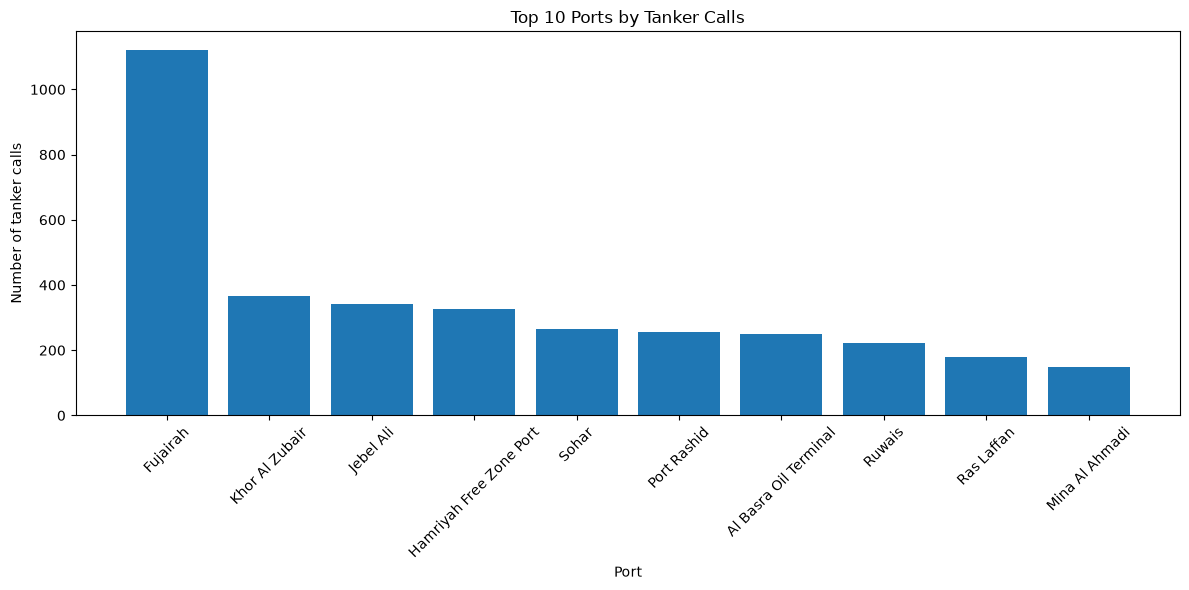

In [50]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_ports["PortName"],
    top_10_ports["Number_of_Calls"]
)

plt.xlabel("Port")
plt.ylabel("Number of tanker calls")
plt.title("Top 10 Ports by Tanker Calls")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 17 – Compare tanker activity before and after the crisis

17.1 Define the crisis date

In [51]:
CRISIS_DATE = pd.Timestamp("2026-02-28")

17.2 Separate the two periods

In [52]:
before_crisis = calls_tanker_geo[
    calls_tanker_geo["Arrival Time"] < CRISIS_DATE
].copy()

after_crisis = calls_tanker_geo[
    calls_tanker_geo["Arrival Time"] >= CRISIS_DATE
].copy()

print("Before crisis:", len(before_crisis))
print("After crisis:", len(after_crisis))

Before crisis: 4395
After crisis: 744


17.3 Calculate the number of calls per port

In [53]:
before_counts = (
    before_crisis.groupby("PortName")
    .size()
    .reset_index(name="Before_Crisis")
)

after_counts = (
    after_crisis.groupby("PortName")
    .size()
    .reset_index(name="After_Crisis")
)

comparison = before_counts.merge(
    after_counts,
    on="PortName",
    how="outer"
).fillna(0)

comparison["Difference"] = (
    comparison["After_Crisis"] -
    comparison["Before_Crisis"]
)

display(
    comparison.sort_values(
        "Difference",
        ascending=False
    ).head(15)
)

,PortName,Before_Crisis,After_Crisis,Difference
33,Mina Salman,0.0,3.0,3.0
39,Nekah,0.0,2.0,2.0
4,Al Jazeera Port,0.0,1.0,1.0
12,Bandar Taheri,0.0,1.0,1.0
13,Basrah,2.0,1.0,-1.0
18,Fereydoon Kenar,1.0,0.0,-1.0
6,Amirabad,1.0,0.0,-1.0
23,Khalifa Bin Salman,1.0,0.0,-1.0
28,Kish Island,1.0,0.0,-1.0
25,Khasab,1.0,0.0,-1.0


17.4 Create a comparison bar chart

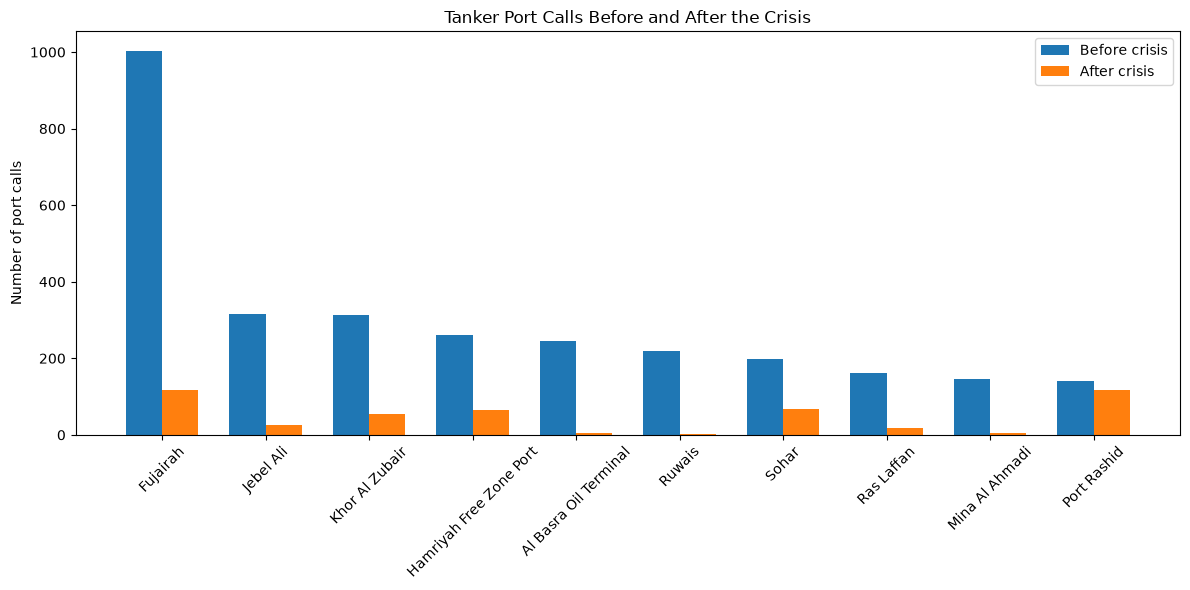

In [54]:
top_ports = comparison.sort_values(
    "Before_Crisis",
    ascending=False
).head(10)

x = np.arange(len(top_ports))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    top_ports["Before_Crisis"],
    width,
    label="Before crisis"
)

plt.bar(
    x + width/2,
    top_ports["After_Crisis"],
    width,
    label="After crisis"
)

plt.xticks(
    x,
    top_ports["PortName"],
    rotation=45
)

plt.ylabel("Number of port calls")
plt.title("Tanker Port Calls Before and After the Crisis")
plt.legend()
plt.tight_layout()
plt.show()

Step 18 – Analyse one Origin-Destination route
18.1 Inspect the worldwide dataset

In [55]:
print(calls_world.columns.tolist())
display(calls_world.head())

['IMO/LR/IHS No.', 'MMSI', 'Ship Name', 'Operator', 'Port', 'Port Zone', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'DWT', 'Arrival Draught', 'Departure Draught', 'Voyage Hours']


,IMO/LR/IHS No.,MMSI,Ship Name,Operator,Port,Port Zone,Arrival Time,Sailed Time,Hours in Port,DWT,Arrival Draught,Departure Draught,Voyage Hours
0,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,FPSO 'Ichthys Venturer',FPSO 'Ichthys Venturer',2025-12-22 07:11:00,2025-12-23 22:11:00,39.000000,114066,8.5,8.5,513.0
1,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Singapore,Jurong,2025-12-29 08:46:00,2025-12-30 16:47:00,32.016667,114066,12.0,8.5,130.0
2,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Sikka,Jamnagar Terminal SPM No 5,2026-01-15 03:16:00,2026-01-16 04:32:00,25.266667,114066,8.5,14.7,371.0
3,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Melbourne,Melbourne Williamstown,2026-02-09 21:31:00,2026-02-13 01:47:00,76.266667,114066,14.7,8.5,593.0
4,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Greater Baton Rouge,Greater Baton Rouge E Bank,2026-04-25 00:22:00,2026-04-28 12:50:00,84.466667,114066,9.5,13.7,1703.0


Step 18 – Origin-Destination (OD) analysis
18.1 What are we investigating?
18.2 Prepare the worldwide tanker dataset

In [56]:
# Convert arrival and departure times

calls_world["Arrival Time"] = pd.to_datetime(
    calls_world["Arrival Time"],
    errors="coerce"
)

calls_world["Sailed Time"] = pd.to_datetime(
    calls_world["Sailed Time"],
    errors="coerce"
)

# Check the results

display(
    calls_world[
        ["Ship Name", "Port", "Arrival Time",
         "Sailed Time", "Voyage Hours"]
    ].head(10)
)

,Ship Name,Port,Arrival Time,Sailed Time,Voyage Hours
0,A LEOPARD,FPSO 'Ichthys Venturer',2025-12-22 07:11:00,2025-12-23 22:11:00,513.0
1,A LEOPARD,Singapore,2025-12-29 08:46:00,2025-12-30 16:47:00,130.0
2,A LEOPARD,Sikka,2026-01-15 03:16:00,2026-01-16 04:32:00,371.0
3,A LEOPARD,Melbourne,2026-02-09 21:31:00,2026-02-13 01:47:00,593.0
4,A LEOPARD,Greater Baton Rouge,2026-04-25 00:22:00,2026-04-28 12:50:00,1703.0
5,A LEOPARD,Amsterdam,2026-05-16 08:16:00,2026-05-20 18:09:00,428.0
6,A LEOPARD,Skikda,2026-05-30 14:30:00,2026-06-02 03:38:00,236.0
7,ABDIAS NASCIMENTO,Gebig,2025-12-27 12:21:00,2025-12-30 20:10:00,1190.0
8,ABDIAS NASCIMENTO,Gebig,2026-01-10 06:42:00,2026-01-12 06:11:00,250.0
9,ABDIAS NASCIMENTO,FSO 'CS Innovation',2026-02-16 09:39:00,2026-02-17 02:00:00,843.0


18.3 Identify the origin and destination

In [57]:
# Sort port calls by vessel and arrival time

calls_world = calls_world.sort_values(
    ["IMO/LR/IHS No.", "Arrival Time"]
).copy()

# Identify previous port for each vessel

calls_world["Origin"] = (
    calls_world.groupby("IMO/LR/IHS No.")["Port"]
    .shift(1)
)

# Current port is the destination

calls_world["Destination"] = calls_world["Port"]

display(
    calls_world[
        ["Ship Name", "Origin", "Destination",
         "Arrival Time", "Voyage Hours"]
    ].head(15)
)

,Ship Name,Origin,Destination,Arrival Time,Voyage Hours
17154,METRO VENETIAN,NaN,Sikka,2025-12-08 04:01:00,477.0
17155,METRO VENETIAN,Sikka,Dar es Salaam,2025-12-19 11:29:00,245.0
17156,METRO VENETIAN,Dar es Salaam,Sikka,2026-01-05 11:15:00,235.0
17157,METRO VENETIAN,Sikka,Singapore,2026-04-17 15:30:00,2431.0
17158,METRO VENETIAN,Singapore,Dalian,2026-04-30 22:09:00,248.0
17159,METRO VENETIAN,Dalian,Sikka,2026-05-23 06:35:00,460.0
12916,ISABELLA,NaN,Sikka,2025-12-21 05:01:00,474.0
12917,ISABELLA,Sikka,Dakar,2026-02-06 08:01:00,1107.0
12918,ISABELLA,Dakar,Greater Tortue Ahmeyim,2026-02-10 17:30:00,98.0
12919,ISABELLA,Greater Tortue Ahmeyim,Rotterdam,2026-02-22 14:16:00,250.0


18.4 Prepare the voyage dataset

In [58]:
voyages = calls_world.dropna(
    subset=[
        "Origin",
        "Destination",
        "Arrival Time",
        "Voyage Hours"
    ]
).copy()

# Remove zero or negative voyage durations

voyages = voyages[
    voyages["Voyage Hours"] > 0
].copy()

display(
    voyages[
        ["Ship Name", "Origin", "Destination",
         "Arrival Time", "Voyage Hours"]
    ].head(15)
)

,Ship Name,Origin,Destination,Arrival Time,Voyage Hours
17155,METRO VENETIAN,Sikka,Dar es Salaam,2025-12-19 11:29:00,245.0
17156,METRO VENETIAN,Dar es Salaam,Sikka,2026-01-05 11:15:00,235.0
17157,METRO VENETIAN,Sikka,Singapore,2026-04-17 15:30:00,2431.0
17158,METRO VENETIAN,Singapore,Dalian,2026-04-30 22:09:00,248.0
17159,METRO VENETIAN,Dalian,Sikka,2026-05-23 06:35:00,460.0
12917,ISABELLA,Sikka,Dakar,2026-02-06 08:01:00,1107.0
12918,ISABELLA,Dakar,Greater Tortue Ahmeyim,2026-02-10 17:30:00,98.0
12919,ISABELLA,Greater Tortue Ahmeyim,Rotterdam,2026-02-22 14:16:00,250.0
12920,ISABELLA,Rotterdam,Corpus Christi,2026-03-16 18:36:00,453.0
12921,ISABELLA,Corpus Christi,Corpus Christi,2026-03-18 20:21:00,40.0


18.5 Identify the most common OD routes

In [59]:
od_counts = (
    voyages.groupby(["Origin", "Destination"])
    .size()
    .reset_index(name="Number_of_Voyages")
    .sort_values("Number_of_Voyages", ascending=False)
)

display(od_counts.head(20))

,Origin,Destination,Number_of_Voyages
8256,Singapore,Singapore,212
5047,Long Beach,Long Beach,121
4502,King Fahd Industrial Port (Yanbu),King Fahd Industrial Port (Yanbu),94
7514,STS Limassol OPL,STS Limassol OPL,77
7040,Quebec,Montreal,76
5809,Montreal,Quebec,72
6689,Port Neches,US Gulf Lightering Zones,72
1330,Corpus Christi,US Gulf Lightering Zones,68
9147,US Gulf Lightering Zones,Port Neches,65
49,Ain Sukhna Terminal,King Fahd Industrial Port (Yanbu),63


18.6 Calculate basic voyage statistics

In [60]:
print("Number of voyages:", len(voyages))

print("\nVoyage duration statistics:")

print(voyages["Voyage Hours"].describe())

Number of voyages: 27519

Voyage duration statistics:
count    27519.000000
mean       280.121661
std        332.573807
min          1.000000
25%         56.000000
50%        150.000000
75%        408.000000
max       3908.000000
Name: Voyage Hours, dtype: float64


Step 19 – Identify ships around Hormuz
19.1 What are we trying to find?
19.3 Set the crisis starting date


In [61]:
# Define the beginning of the Hormuz crisis
# Replace this with the date confirmed by your professor

CRISIS_DATE = pd.Timestamp("2026-02-28 00:00:00")

print("Crisis started:", CRISIS_DATE)

Crisis started: 2026-02-28 00:00:00


19.4 Prepare the regional port dataset

In [62]:
# Make copies to protect original datasets

tanker_data = calls_tanker.copy()
hormuz_ports = ports_detroit_ormuz.copy()

# Clean port names

tanker_data["Port_clean"] = (
    tanker_data["Port"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

hormuz_ports["Port_clean"] = (
    hormuz_ports["Port"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Identify the port names belonging to the Hormuz region

regional_port_names = hormuz_ports["Port_clean"].dropna().unique()

# Keep only tanker calls at the 64 regional ports

tanker_hormuz = tanker_data[
    tanker_data["Port_clean"].isin(regional_port_names)
].copy()

print("Total tanker records:", len(tanker_data))
print("Records at Hormuz ports:", len(tanker_hormuz))

print(
    "Number of regional ports represented:",
    tanker_hormuz["Port_clean"].nunique()
)

Total tanker records: 5139
Records at Hormuz ports: 5139
Number of regional ports represented: 56


19.5 Convert arrival and departure times

In [63]:
tanker_hormuz["Arrival Time"] = pd.to_datetime(
    tanker_hormuz["Arrival Time"],
    errors="coerce"
)

tanker_hormuz["Sailed Time"] = pd.to_datetime(
    tanker_hormuz["Sailed Time"],
    errors="coerce"
)

# Remove records without valid arrival or departure times

tanker_hormuz = tanker_hormuz.dropna(
    subset=["Arrival Time", "Sailed Time"]
).copy()

# Check chronological consistency

tanker_hormuz = tanker_hormuz[
    tanker_hormuz["Sailed Time"] >=
    tanker_hormuz["Arrival Time"]
].copy()

print("Valid regional port calls:", len(tanker_hormuz))

Valid regional port calls: 5137


19.6 Identify ships present when the crisis began

In [64]:
ships_present = tanker_hormuz[
    (tanker_hormuz["Arrival Time"] <= CRISIS_DATE) &
    (tanker_hormuz["Sailed Time"] >= CRISIS_DATE)
].copy()

print("Number of port-call records:", len(ships_present))

print(
    "Number of unique ships:",
    ships_present["IMO/LR/IHS No."].nunique()
)

Number of port-call records: 142
Number of unique ships: 142


19.7 Display the ships identified

In [65]:
ships_present_table = ships_present[
    [
        "IMO/LR/IHS No.",
        "Ship Name",
        "Vessel Type",
        "Port",
        "Arrival Time",
        "Sailed Time",
        "Hours in Port",
        "DWT"
    ]
].sort_values("Port")

display(ships_present_table)

,IMO/LR/IHS No.,Ship Name,Vessel Type,Port,Arrival Time,Sailed Time,Hours in Port,DWT
1003,9907445,CYPRES,TANKER,Al Basra Oil Terminal,2026-02-27 01:31:00,2026-03-02 15:02:00,85.516667,158388
1206,9597264,EAGLE VERONA,TANKER,Al Basra Oil Terminal,2026-02-26 00:31:00,2026-02-28 04:15:00,51.733333,320122
1599,9845130,FRONT SAMARA,TANKER,Al Basra Oil Terminal,2026-02-27 12:46:00,2026-02-28 22:14:00,33.466667,157271
2611,9886641,MIAOULIS 21,TANKER,Al Basra Oil Terminal,2026-02-26 22:29:00,2026-02-28 14:17:00,39.800000,158081
3748,9330563,SANMAR HERALD,TANKER,Al Basra Oil Terminal,2026-02-27 21:47:00,2026-03-01 12:30:00,38.716667,320475
...,...,...,...,...,...,...,...,...
3234,9204049,OPHELIA I,TANKER,Umm Qasr,2026-02-27 05:00:00,2026-02-28 19:02:00,38.033333,14895
3696,9718820,SADAH SILVER,TANKER,Umm Qasr,2026-02-26 19:15:00,2026-02-28 12:39:00,41.400000,49734
4041,9888637,SHOKO,TANKER,Umm Qasr,2026-02-27 08:31:00,2026-02-28 21:01:00,36.500000,11653
5101,9310692,ZEUS,TANKER,Umm Qasr,2026-02-27 17:31:00,2026-03-04 01:32:00,104.016667,48539


19.8 Count ships at each port

In [66]:
ships_per_port = (
    ships_present
    .groupby("Port")
    .agg(
        Number_of_Ships=("IMO/LR/IHS No.", "nunique"),
        Number_of_Records=("IMO/LR/IHS No.", "size"),
        Average_DWT=("DWT", "mean")
    )
    .reset_index()
    .sort_values("Number_of_Ships", ascending=False)
)

display(ships_per_port)

,Port,Number_of_Ships,Number_of_Records,Average_DWT
20,Port Rashid,25,25,94284.400000
6,Fujairah,14,14,31862.142857
10,Khor Al Zubair,12,12,56457.916667
8,Hamriyah Free Zone Port,10,10,14110.800000
24,Sharjah,9,9,22335.111111
1,Al Duqm,7,7,52540.285714
0,Al Basra Oil Terminal,7,7,227274.857143
9,Jebel Ali,6,6,44625.166667
26,Sitra,5,5,57969.400000
22,Ruwais,5,5,59917.000000


19.9 Investigate what happened to these ships after the crisis began

In [67]:
ships_present["Departure_After_Crisis_Hours"] = (
    ships_present["Sailed Time"] - CRISIS_DATE
).dt.total_seconds() / 3600

ships_present["Departure_After_Crisis_Days"] = (
    ships_present["Departure_After_Crisis_Hours"] / 24
)

display(
    ships_present[
        [
            "Ship Name",
            "Port",
            "Arrival Time",
            "Sailed Time",
            "Departure_After_Crisis_Days"
        ]
    ].sort_values("Departure_After_Crisis_Days")
)

,Ship Name,Port,Arrival Time,Sailed Time,Departure_After_Crisis_Days
2515,MARUTI,Fujairah,2026-02-27 00:59:00,2026-02-28 00:29:00,0.020139
3107,OCEAN LAURA,Fujairah,2026-02-25 18:16:00,2026-02-28 00:30:00,0.020833
1503,FNSA 10,Fujairah,2026-02-27 11:59:00,2026-02-28 01:02:00,0.043056
114,AKTI A,Sitra,2026-02-26 11:59:00,2026-02-28 02:02:00,0.084722
5102,ZEZE START,Ruwais,2026-02-27 01:58:00,2026-02-28 02:47:00,0.115972
...,...,...,...,...,...
4334,STELLAR STREAM-7,Al Duqm,2026-01-22 13:13:00,2026-03-30 18:57:00,30.789583
1523,FNSA 11,Port Rashid,2026-02-24 13:31:00,2026-04-29 07:09:00,60.297917
993,CS ANTHEM,Ras Laffan,2026-02-27 22:13:00,2026-05-07 04:27:00,68.185417
3784,SARDASHT,Bandar Abbas,2026-01-27 21:54:00,2026-06-16 02:37:00,108.109028


19.10 Create a map of ships present at the beginning of the crisis

In [68]:
import folium

# Attach geographical coordinates to the identified ships

ships_map_data = ships_present.merge(
    hormuz_ports[
        ["Port_clean", "LatitudeDecimal", "LongitudeDecimal"]
    ].drop_duplicates("Port_clean"),
    on="Port_clean",
    how="left"
)

# Remove missing coordinates

ships_map_data = ships_map_data.dropna(
    subset=["LatitudeDecimal", "LongitudeDecimal"]
)

# Create map

m_ships = folium.Map(
    location=[
        ships_map_data["LatitudeDecimal"].mean(),
        ships_map_data["LongitudeDecimal"].mean()
    ],
    zoom_start=6,
    tiles="CartoDB positron"
)

# Add ship markers

for _, row in ships_map_data.iterrows():

    folium.CircleMarker(
        location=[
            row["LatitudeDecimal"],
            row["LongitudeDecimal"]
        ],
        radius=5,
        popup=(
            f'Ship: {row["Ship Name"]}<br>'
            f'Port: {row["Port"]}<br>'
            f'IMO: {row["IMO/LR/IHS No."]}'
        ),
        tooltip=row["Ship Name"],
        color="red",
        fill=True,
        fill_opacity=0.7
    ).add_to(m_ships)

m_ships

In [69]:
m_ships.save("Ships_Present_At_Hormuz_Crisis.html")

19.11 Prepare a summary for your research report

In [70]:
summary_19 = pd.DataFrame({
    "Indicator": [
        "Total regional port calls",
        "Port calls overlapping crisis start",
        "Unique ships present",
        "Number of ports with ships present",
        "Average DWT of ships present"
    ],
    "Value": [
        len(tanker_hormuz),
        len(ships_present),
        ships_present["IMO/LR/IHS No."].nunique(),
        ships_present["Port"].nunique(),
        ships_present["DWT"].mean()
    ]
})

display(summary_19.round(2))

,Indicator,Value
0,Total regional port calls,5137.00
1,Port calls overlapping crisis start,142.00
2,Unique ships present,142.00
3,Number of ports with ships present,31.00
4,Average DWT of ships present,70479.62


Step 20.1 – Define the crisis date and analysis periods